# 02 Similarity: คำทำนายของ 12 ราศีต่างกันจริงไหม

**เจ้าของ:** Member 3 · **ข้อมูล:** `data/processed/horoscopes.csv`

**คำถาม (วัตถุประสงค์ข้อ 1):** คำทำนายของแต่ละราศีคล้ายกันแค่ไหน ถ้าเขียนกว้างๆ จนใช้กับใครก็ได้ (Barnum effect)
คำทำนายของราศีต่างๆ ควรคล้ายกันพอๆ กับคำทำนายของราศีเดียวกัน

**วิธี (L6 TF-IDF, L9 cosine similarity):** วิเคราะห์ 2 ระดับ
1. **ระดับเอกสารรวม** (ตามแผนเดิม): รวมทุกข้อความของราศีเดียวกันเป็น 1 เอกสาร → TF-IDF → cosine → heatmap 12×12
   และทำแบบเดียวกันกับ 4 เว็บ (heatmap 4×4)
2. **ระดับข้อความเดี่ยว** (เพิ่มเพื่อควบคุมผลของผู้เขียน): คำนวณ cosine ของข้อความทุกคู่ (1,233 ข้อความ ≈ 760,000 คู่)
   แล้วเทียบว่า **"ราศีเดียวกัน"** คล้ายกันมากกว่า **"คนละราศี"** ไหม **ภายในเว็บเดียวกัน** และทดสอบด้วย **permutation test**

ทำไมต้องมีระดับที่ 2: ในระดับที่ 1 เอกสารของทุกราศีมีข้อความจากทั้ง 4 เว็บในสัดส่วนเท่ากัน จึงคล้ายกันอยู่แล้วโดยโครงสร้าง
ส่วนระดับที่ 2 เทียบข้อความจากผู้เขียนคนเดียวกัน จึงแยกผลของ "ราศี" ออกจากผลของ "คนเขียน" ได้

In [1]:
import sys
from itertools import chain
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import THAI_FONT, ZODIAC_TH, clean_text, tokenize

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
SITES = ["marumura", "sanook", "thairath", "kapook"]
SITE_COLORS = {"marumura": "#2a78d6", "sanook": "#eb6834", "thairath": "#1baf7a", "kapook": "#eda100"}
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}

# Sequential color scale for similarity: one blue hue, light (0) -> dark (1)
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
BLUE_RAMP.set_bad("#f0efec")  # the diagonal (a group compared with itself) is hidden in grey
SAME_COLOR, DIFF_COLOR = "#52514e", "#c3c2b7"  # "same sign" vs "different sign" bars (neutral, not site colors)

## 1) โหลดข้อมูลและตัดคำ

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv")
df["tokens"] = df["text"].apply(lambda t: tokenize(clean_text(t)))
# text_strict differs from text only for sanook rows -> tokenize only those again (saves time)
df["tokens_strict"] = [tok if strict == text else tokenize(clean_text(strict))
                       for tok, text, strict in zip(df["tokens"], df["text"], df["text_strict"])]
print(df.shape, "| sanook rows where text_strict differs:", (df["text"] != df["text_strict"]).sum())

def identity(words):
    """Texts are already tokenized lists, so TF-IDF must not split them again."""
    return words

(1233, 12) | sanook rows where text_strict differs: 309


## 2) ระดับเอกสารรวม: 1 ราศี = 1 เอกสาร, 1 เว็บ = 1 เอกสาร

ฟังก์ชัน `group_similarity` รวมคำของทุกข้อความในกลุ่มเดียวกันเป็นเอกสารเดียว แล้วคำนวณ TF-IDF และ cosine similarity ระหว่างกลุ่ม

In [3]:
def group_similarity(data, by, order, col="tokens"):
    """Join all texts of each group into one document -> TF-IDF -> cosine similarity matrix."""
    docs = [list(chain.from_iterable(data.loc[data[by] == g, col])) for g in order]
    X = TfidfVectorizer(analyzer=identity).fit_transform(docs)
    return pd.DataFrame(cosine_similarity(X), index=order, columns=order)

def off_diagonal(mat):
    """Values above the diagonal (each pair once, without a group compared with itself)."""
    return mat.values[np.triu_indices(len(mat), 1)]

sim_sign = group_similarity(df, "zodiac", SIGNS)
sim_site = group_similarity(df, "source", SITES)
sim_sign_strict = group_similarity(df, "zodiac", SIGNS, col="tokens_strict")
pd.DataFrame({
    "เปรียบเทียบ": ["ราศี vs ราศี (66 คู่)", "ราศี vs ราศี, text_strict", "เว็บ vs เว็บ (6 คู่)"],
    "cosine เฉลี่ย": [off_diagonal(m).mean() for m in (sim_sign, sim_sign_strict, sim_site)],
    "ต่ำสุด": [off_diagonal(m).min() for m in (sim_sign, sim_sign_strict, sim_site)],
    "สูงสุด": [off_diagonal(m).max() for m in (sim_sign, sim_sign_strict, sim_site)],
}).round(3)

,เปรียบเทียบ,cosine เฉลี่ย,ต่ำสุด,สูงสุด
0,ราศี vs ราศี (66 คู่),0.799,0.682,0.912
1,"ราศี vs ราศี, text_strict",0.913,0.870,0.934
2,เว็บ vs เว็บ (6 คู่),0.432,0.265,0.655


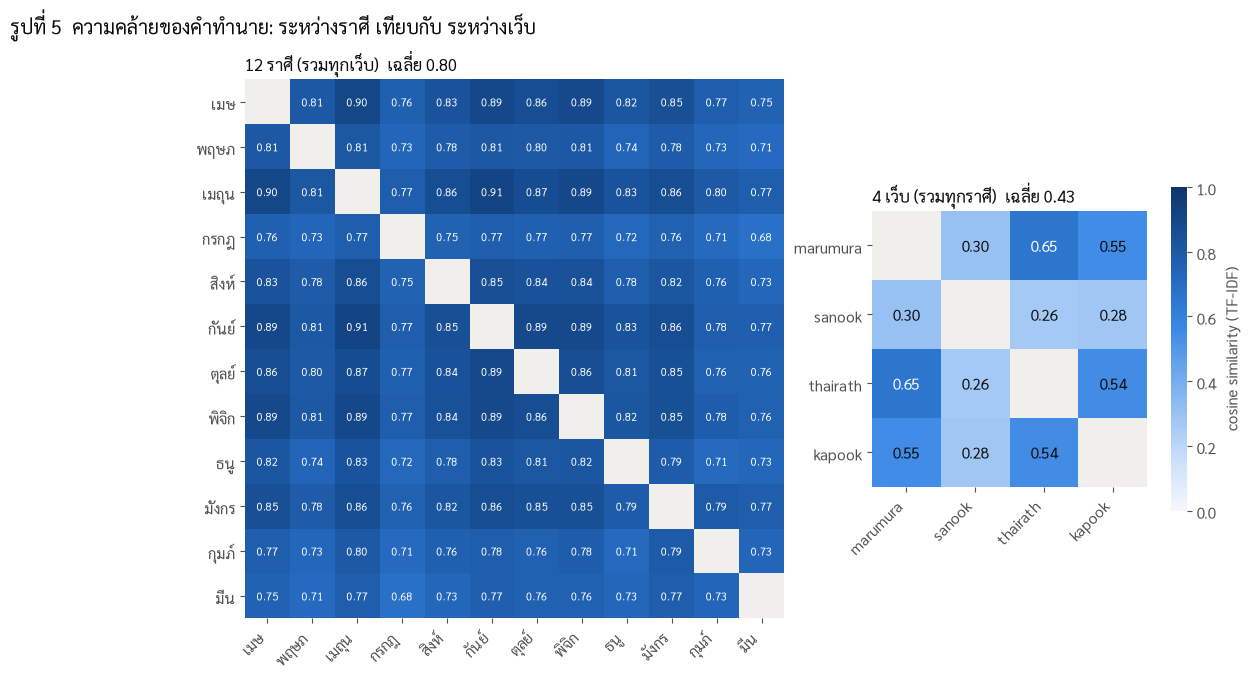

In [4]:
# Figure 1: 12x12 sign heatmap and 4x4 site heatmap on the SAME 0-1 color scale
def draw_heatmap(ax, mat, labels, fontsize):
    values = mat.values.copy()
    np.fill_diagonal(values, np.nan)                       # hide self-similarity (always 1)
    im = ax.imshow(values, cmap=BLUE_RAMP, vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if i != j:
                v = values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=fontsize,
                        color="white" if v > 0.55 else "#0b0b0b")
    return im

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [12, 5.5]})
draw_heatmap(ax1, sim_sign, [f"{SIGN_TH[z]}" for z in SIGNS], fontsize=8)
ax1.set_title(f"12 ราศี (รวมทุกเว็บ)  เฉลี่ย {off_diagonal(sim_sign).mean():.2f}", loc="left")
im = draw_heatmap(ax2, sim_site, SITES, fontsize=11)
ax2.set_title(f"4 เว็บ (รวมทุกราศี)  เฉลี่ย {off_diagonal(sim_site).mean():.2f}", loc="left")
cbar = fig.colorbar(im, ax=[ax1, ax2], shrink=0.6, pad=0.02)
cbar.set_label("cosine similarity (TF-IDF)")
cbar.outline.set_visible(False)
fig.suptitle("รูปที่ 5  ความคล้ายของคำทำนาย: ระหว่างราศี เทียบกับ ระหว่างเว็บ", x=0.01, ha="left", fontsize=14)
fig.savefig(FIG_DIR / "02_heatmap_sign_vs_site.png")
plt.show()

**จากรูปที่ 5 พบว่า**
- **ระหว่างราศี** (ซ้าย) คล้ายกันมาก cosine เฉลี่ย **0.80** (0.68–0.91) ทั้ง heatmap เป็นสีน้ำเงินเข้มเกือบเท่ากันหมด
- **ระหว่างเว็บ** (ขวา) คล้ายกันน้อยกว่ามาก เฉลี่ย **0.43** (0.26–0.65) และ **sanook ต่างจากทุกเว็บที่สุด** (0.26–0.30) เพราะใช้ศัพท์โหราศาสตร์ (ดาว เขต สถิต โคจร)
- **ราศีคู่ที่ต่างกันที่สุด** (ราศีกรกฎกับราศีมีน 0.68) ยังคล้ายกันมากกว่า **เว็บคู่ที่เหมือนกันที่สุด** (marumura กับ thairath 0.65)

ราศีที่ดูต่างจากราศีอื่นบ้าง (สีอ่อนกว่า) คือ ราศีพฤษภ ราศีกรกฎ ราศีกุมภ์ และราศีมีน ซึ่งตรงกับราศีที่ส่วน **"คำแนะนำ" ของ sanook ยาวที่สุด** (ดูโน้ตบุ๊ก 01)
เมื่อใช้ `text_strict` ที่ตัดส่วนนี้ออก ความคล้ายระหว่างราศี**เพิ่มเป็น 0.91** (0.87–0.93) แปลว่า 12 ราศีแทบเป็นเอกสารเดียวกัน
ความต่างระหว่างราศีที่เห็นจึงมาจากข้อความเรื่องดาวประจำราศีที่ sanook ใช้ซ้ำ ไม่ได้มาจากคำทำนาย

*ข้อควรระวัง:* เอกสารของแต่ละราศีมีข้อความจากทั้ง 4 เว็บในสัดส่วนเท่ากัน จึงคล้ายกันได้ส่วนหนึ่งเพราะวิธีรวมเอกสาร ส่วนที่ 3 ด้านล่างจึงเทียบที่ระดับข้อความเดี่ยวเพื่อตัดปัญหานี้

## 3) ระดับข้อความเดี่ยว: ราศีเดียวกันคล้ายกันมากกว่าคนละราศีไหม

คำนวณ TF-IDF จากข้อความทั้ง 1,233 ข้อความ (`min_df=2` ตัดคำที่โผล่แค่ครั้งเดียวทิ้ง) แล้วหา cosine ของ**ทุกคู่ข้อความ**
จากนั้นแบ่งคู่ข้อความเป็น 4 กลุ่ม: เว็บเดียวกันหรือคนละเว็บ × ราศีเดียวกันหรือคนละราศี

In [5]:
def pair_table(data, col="tokens"):
    """Cosine similarity of every pair of texts, with labels: same site? same sign?"""
    X = TfidfVectorizer(analyzer=identity, min_df=2).fit_transform(data[col])
    S = cosine_similarity(X)
    i, j = np.triu_indices(len(data), 1)                   # every pair once
    site, sign = data["source"].to_numpy(), data["zodiac"].to_numpy()
    return pd.DataFrame({"site_i": site[i], "same_site": site[i] == site[j],
                         "same_sign": sign[i] == sign[j], "cos": S[i, j]})

pairs = pair_table(df)
summary_2x2 = (pairs.groupby(["same_site", "same_sign"])["cos"].agg(["mean", "size"])
               .rename(index={True: "ใช่", False: "ไม่ใช่"}).round(4))
summary_2x2.index.names = ["เว็บเดียวกัน", "ราศีเดียวกัน"]
summary_2x2

mean    size
เว็บเดียวกัน ราศีเดียวกัน                
ไม่ใช่       ไม่ใช่        0.0396  522555
             ใช่           0.0395   47505
ใช่          ไม่ใช่        0.1321  174243
             ใช่           0.1759   15225

### Permutation test (ทดสอบว่าความต่างเกิดขึ้นโดยบังเอิญได้ไหม)

ภายในแต่ละเว็บ ค่าที่ดูคือ **d = cosine เฉลี่ยของคู่ราศีเดียวกัน − cosine เฉลี่ยของคู่คนละราศี**
แล้วสุ่มสลับป้ายราศีของข้อความในเว็บนั้น 1,000 ครั้ง (ราวกับว่าราศีไม่มีความหมาย) และคำนวณ d ใหม่ทุกครั้ง
**p-value** = สัดส่วนครั้งที่ d จากการสุ่มมากกว่าหรือเท่ากับ d จริง ถ้า p < 0.05 แปลว่าราศีเดียวกันคล้ายกันมากกว่าที่ความบังเอิญจะอธิบายได้

In [6]:
def sign_effect(data, col="tokens", n_perm=1000, seed=42):
    """Per site: mean cosine of same-sign pairs vs different-sign pairs + permutation p-value."""
    X = TfidfVectorizer(analyzer=identity, min_df=2).fit_transform(data[col])
    S = cosine_similarity(X)
    rng = np.random.default_rng(seed)
    rows = []
    for site in SITES:
        idx = np.where(data["source"].to_numpy() == site)[0]
        i, j = np.triu_indices(len(idx), 1)
        sims = S[np.ix_(idx, idx)][i, j]
        labels = data["zodiac"].to_numpy()[idx]

        def same_minus_diff(lab):
            same = lab[i] == lab[j]
            return sims[same].mean() - sims[~same].mean()

        observed = same_minus_diff(labels)
        null = np.array([same_minus_diff(rng.permutation(labels)) for _ in range(n_perm)])
        same = sims[labels[i] == labels[j]].mean()
        diff = sims[labels[i] != labels[j]].mean()
        rows.append({"site": site, "n_texts": len(idx), "same_sign": same, "diff_sign": diff,
                     "ratio": same / diff, "p_value": (1 + (null >= observed).sum()) / (n_perm + 1)})
    return pd.DataFrame(rows).set_index("site")

effect_text = sign_effect(df, "tokens")
effect_strict = sign_effect(df, "tokens_strict")
effect_text.round(4)

,n_texts,same_sign,diff_sign,ratio,p_value
site,,,,,
marumura,312,0.0703,0.0668,1.0521,0.0010
sanook,309,0.4332,0.2641,1.6404,0.0010
thairath,300,0.0941,0.0928,1.0139,0.0679
kapook,312,0.1046,0.1042,1.0039,0.1618


C:\Users\Jamvess\AppData\Local\Temp\ipykernel_42220\831383993.py:24: UserWarning: Glyph 8804 (\N{LESS-THAN OR EQUAL TO}) missing from font(s) Sarabun.
  fig.tight_layout()
C:\Users\Jamvess\AppData\Local\Temp\ipykernel_42220\831383993.py:25: UserWarning: Glyph 8804 (\N{LESS-THAN OR EQUAL TO}) missing from font(s) Sarabun.
  fig.savefig(FIG_DIR / "02_sign_effect_within_site.png")


C:\Users\Jamvess\Downloads\horoscope-project\horoscope-project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8804 (\N{LESS-THAN OR EQUAL TO}) missing from font(s) Sarabun.
  fig.canvas.print_figure(bytes_io, **kw)


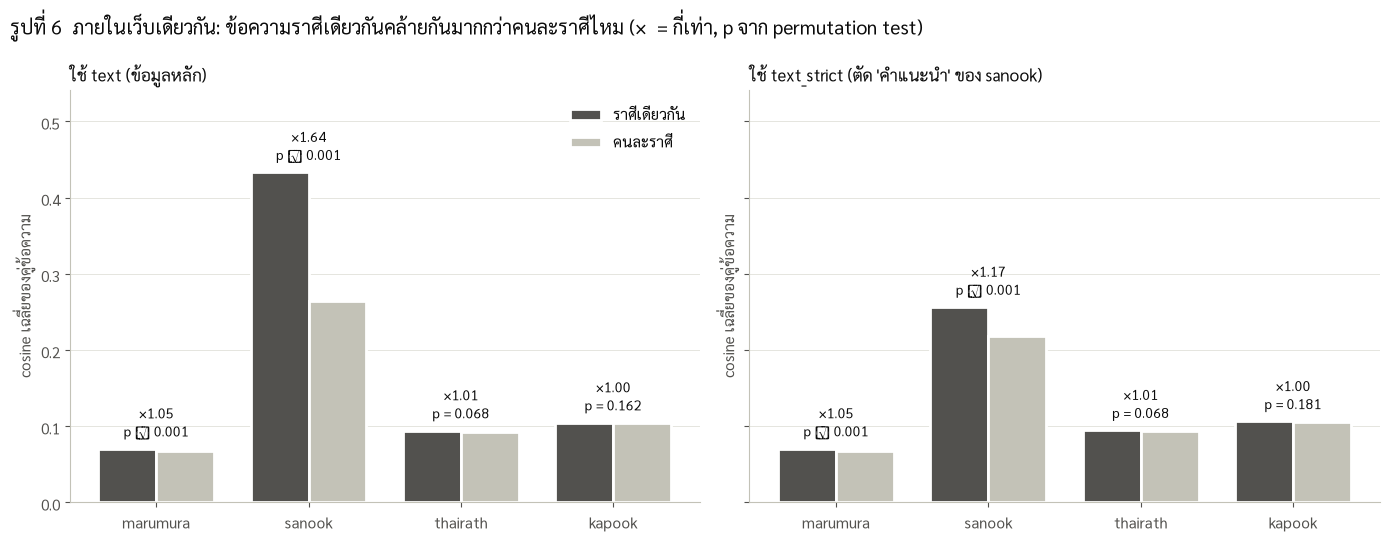

In [7]:
# Figure 6: same-sign vs different-sign similarity inside each site, for text and text_strict
def draw_effect(ax, eff, title):
    x = np.arange(len(SITES))
    w = 0.38
    ax.bar(x - w / 2, eff["same_sign"], w, color=SAME_COLOR, label="ราศีเดียวกัน", edgecolor="white", linewidth=2)
    ax.bar(x + w / 2, eff["diff_sign"], w, color=DIFF_COLOR, label="คนละราศี", edgecolor="white", linewidth=2)
    for k, site in enumerate(SITES):
        r, p = eff.loc[site, "ratio"], eff.loc[site, "p_value"]
        top = max(eff.loc[site, "same_sign"], eff.loc[site, "diff_sign"])
        p_text = "p ≤ 0.001" if p < 0.0011 else f"p = {p:.3f}"   # 1,000 shuffles -> smallest p is 1/1001
        ax.text(k, top + 0.012, f"×{r:.2f}\n{p_text}", ha="center", va="bottom", fontsize=10, color="#0b0b0b")
    ax.set_xticks(x, SITES)
    ax.set_ylabel("cosine เฉลี่ยของคู่ข้อความ")
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
draw_effect(axes[0], effect_text, "ใช้ text (ข้อมูลหลัก)")
draw_effect(axes[1], effect_strict, "ใช้ text_strict (ตัด 'คำแนะนำ' ของ sanook)")
axes[0].set_ylim(0, max(effect_text["same_sign"].max(), effect_strict["same_sign"].max()) * 1.25)
axes[0].legend(frameon=False, loc="upper right")
fig.suptitle("รูปที่ 6  ภายในเว็บเดียวกัน: ข้อความราศีเดียวกันคล้ายกันมากกว่าคนละราศีไหม (×  = กี่เท่า, p จาก permutation test)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sign_effect_within_site.png")
plt.show()

**จากตารางและรูปที่ 6 พบว่า**

**ตาราง 2×2 (ทุกคู่ข้อความ):**
- ข้อความ**คนละเว็บ**: ราศีเดียวกัน (0.0395) กับคนละราศี (0.0396) **เท่ากัน** แปลว่าเมื่อคนเขียนต่างกัน การเป็นราศีเดียวกันไม่ได้ทำให้ข้อความคล้ายกันขึ้นเลย
- ข้อความ**เว็บเดียวกันแต่คนละราศี** (0.132) คล้ายกันมากกว่า**ราศีเดียวกันแต่คนละเว็บ** (0.039) ถึง **3.4 เท่า** แปลว่า **"ใครเขียน" สำคัญกว่า "ราศีอะไร" มาก**

**รูปที่ 6 (ภายในแต่ละเว็บ):**
- **thairath (×1.01, p = 0.068) และ kapook (×1.00, p = 0.16):** ราศีเดียวกันไม่ได้คล้ายกันมากกว่าคนละราศี เป็นคำทำนายที่**สลับราศีกันได้**
- **marumura (×1.05, p ≤ 0.001):** มีผลเล็กน้อย แต่ส่วนที่ 4 แสดงว่า**มาจากข้อความที่ลอกซ้ำ**ทั้งหมด
- **sanook (×1.64):** เป็นเว็บเดียวที่ราศีเดียวกันคล้ายกันชัดเจน แต่เมื่อตัดส่วน "คำแนะนำ" ที่ใช้ซ้ำออก (`text_strict`) เหลือแค่ **×1.17** (ยังมีนัยสำคัญ p ≤ 0.001)
  ส่วนที่ยังเหลือน่าจะมาจากเนื้อหาโหราศาสตร์จริงของ sanook ที่อ้างอิงดาวและตำแหน่งดาวของแต่ละราศี

## 4) ตรวจความทนทานของผล (robustness)

ผลยังเหมือนเดิมไหมถ้า (ก) ตัดข้อความที่ลอกจากสัปดาห์ก่อน (`near_duplicate`) ออก และ (ข) ใช้ `text_strict`

In [8]:
no_dup = df[~df["near_duplicate"]].reset_index(drop=True)
variants = {
    "text": effect_text,
    "text_strict": effect_strict,
    "text, ไม่มี near_duplicate": sign_effect(no_dup, "tokens"),
    "text_strict, ไม่มี near_duplicate": sign_effect(no_dup, "tokens_strict"),
}
robust = pd.concat(variants, names=["ข้อมูล"])[["n_texts", "same_sign", "diff_sign", "ratio", "p_value"]]
robust.round(4)

n_texts  same_sign  diff_sign  \
ข้อมูล                            site                                      
text                              marumura      312     0.0703     0.0668   
                                  sanook        309     0.4332     0.2641   
                                  thairath      300     0.0941     0.0928   
                                  kapook        312     0.1046     0.1042   
text_strict                       marumura      312     0.0705     0.0671   
                                  sanook        309     0.2563     0.2187   
                                  thairath      300     0.0946     0.0933   
                                  kapook        312     0.1062     0.1058   
text, ไม่มี near_duplicate        marumura      284     0.0686     0.0679   
                                  sanook        281     0.4086     0.2642   
                                  thairath      300     0.0940     0.0928   
                                  kapook        312     0.1037     0.1033   
text_strict, ไม่มี near_duplicate marumura      284     0.0688     0.0682   
                                  sanook        281     0.2569     0.2217   
                                  thairath      300     0.0945     0.0932   
                                  kapook        312     0.1050     0.1047   

                                             ratio  p_value  
ข้อมูล                            site                       
text                              marumura  1.0521   0.0010  
                                  sanook    1.6404   0.0010  
                                  thairath  1.0139   0.0679  
                                  kapook    1.0039   0.1618  
text_strict                       marumura  1.0504   0.0010  
                                  sanook    1.1719   0.0010  
                                  thairath  1.0137   0.0679  
                                  kapook    1.0035   0.1808  
text, ไม่มี near_duplicate        marumura  1.0109   0.1399  
                                  sanook    1.5464   0.0010  
                                  thairath  1.0139   0.0679  
                                  kapook    1.0040   0.1708  
text_strict, ไม่มี near_duplicate marumura  1.0096   0.1678  
                                  sanook    1.1589   0.0010  
                                  thairath  1.0137   0.0679  
                                  kapook    1.0036   0.1948

**จากตาราง robustness พบว่า**
- **marumura:** เมื่อตัดข้อความที่ลอกซ้ำ (`near_duplicate`) ออก ผลลดจาก ×1.05 (p ≤ 0.001) เหลือ **×1.01 (p = 0.14) ไม่มีนัยสำคัญ**
  แปลว่าความต่างระหว่างราศีของ marumura เกิดจากการนำคำทำนายเก่ามาใช้กับราศีเดิมเท่านั้น ตัวคำทำนายที่เขียนใหม่ไม่ได้ต่างกันตามราศี
- **thairath และ kapook:** ไม่มีนัยสำคัญในทุกแบบ (p = 0.07–0.19) ผลคงที่
- **sanook:** มีนัยสำคัญในทุกแบบ แต่ขนาดผลขึ้นกับว่าตัดส่วน "คำแนะนำ" หรือไม่ (×1.55–1.64 ถ้าไม่ตัด, ×1.16–1.17 ถ้าตัด)

ผลหลักจึงไม่เปลี่ยนไม่ว่าจะเลือกข้อมูลแบบไหน คือ 3 ใน 4 เว็บไม่มีความต่างระหว่างราศีที่เกิดจากเนื้อหาคำทำนายจริง

## สรุปผล 02 Similarity (ตอบวัตถุประสงค์ข้อ 1 ส่วนแรก)

1. **12 ราศีคล้ายกันมากกว่า 4 เว็บ:** ถ้ารวมเป็นเอกสาร ระหว่างราศีได้ cosine 0.80 (เพิ่มเป็น 0.91 เมื่อตัดคำแนะนำที่ใช้ซ้ำของ sanook) ส่วนระหว่างเว็บได้ 0.43 (รูปที่ 5)
2. **คนเขียนสำคัญกว่าราศี:** ข้อความเว็บเดียวกันแต่คนละราศีคล้ายกันมากกว่าราศีเดียวกันแต่คนละเว็บ 3.4 เท่า และข้ามเว็บไปแล้วการเป็นราศีเดียวกันไม่ทำให้คล้ายกันขึ้นเลย
3. **ภายในเว็บ:** thairath และ kapook ไม่มีความต่างระหว่างราศี ส่วน marumura มีความต่างเฉพาะจากข้อความที่ลอกซ้ำ ส่วน sanook มีความต่างที่มาจากส่วนคำแนะนำเรื่องดาวประจำราศีเป็นหลัก และยังเหลือความต่างเล็กน้อย (×1.17) หลังตัดออก (รูปที่ 6 และตาราง robustness)

**เชื่อมกับคำถามวิจัย:** ผลสนับสนุน **Barnum effect** อย่างชัดเจนสำหรับ 3 ใน 4 เว็บ คำทำนายของแต่ละราศีแทบไม่ต่างกัน และความต่างที่วัดได้มาจาก**ผู้เขียน**
ข้อยกเว้นเดียวคือ sanook ที่เขียนอิงตำแหน่งดาวของแต่ละราศี จึงมีความเฉพาะราศีอยู่บ้าง

**ส่งต่อให้โน้ตบุ๊ก 03 (classification):** คาดว่า**การทายเว็บจะแม่นมาก** ส่วน**การทายราศีจะใกล้ระดับเดา (8.3%)** ยกเว้นข้อความของ sanook ควรรายงานผลแยกตามเว็บ และทั้งแบบ `text` กับ `text_strict`

**รูปที่บันทึกไว้:** `outputs/figures/02_heatmap_sign_vs_site.png`, `02_sign_effect_within_site.png`